<a href="https://colab.research.google.com/github/eliasbelme/eliasbelme.github.io/blob/main/TPGP27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== ÉTAPE 1 : Chargement et Feature Engineering initial ===
Jeu de données chargé : 10886 observations et 12 variables explicatives.
Variables : ['season', 'holiday', 'workingday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'hour', 'month', 'dayofweek', 'year']

=== ÉTAPE 2 : Data Engineering (Sélection Lasso) ===
Le Lasso a conservé 10 variables pertinentes : ['holiday', 'weather', 'temp', 'atemp', 'humidity', 'windspeed', 'hour', 'month', 'dayofweek', 'year']

=== ÉTAPE 3 : Implémentation (Cross-Validation) ===

Résultats CV (Erreur RMSE) :
            Modèle  RMSE_CV_moyen
    Random Forest      42.537192
Gradient Boosting      67.377349
Linear Regression     141.889286
            Lasso     141.895510

Modèle offrant la meilleure précision : Random Forest

=== ÉTAPE 4 : Optimisation de Stock (FBNV Newsvendor) ===

=== ÉTAPE 5 : Production et Résultats ===
Performance (Équivalent Table 8) - RMSE: 68.76 | MAE: 45.53 | R²: 0.856

Validation du papier de recherche (Équivalent

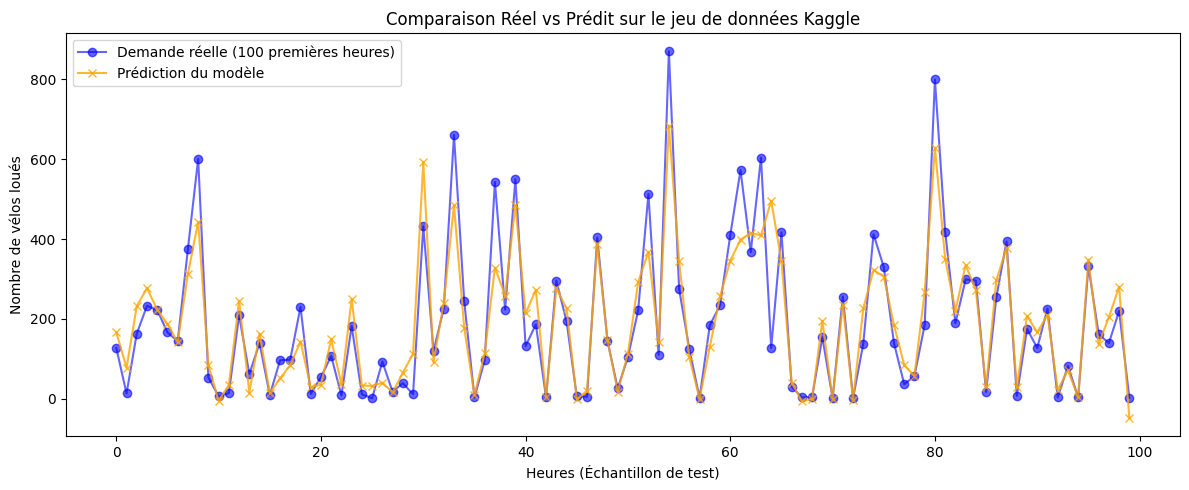

In [ ]:
"""
PIPELINE EN 5 ÉTAPES - Projet GP27 (Gestion des stocks / Prévision de la demande)
Jeu de données : Bike Sharing Demand (Kaggle)
Reproduction du modèle FBNV (Feature Based Newsvendor) - Jing Shi (2022)
"""

# Activation de l'affichage des graphiques dans le notebook
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import norm

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ==============================================================================
# ÉTAPE 1 : CHARGEMENT ET ANALYSE DES DONNÉES (Dataset Bike Sharing)
# ==============================================================================
print("=== ÉTAPE 1 : Chargement et Feature Engineering initial ===")

# Chargement du fichier Kaggle
df = pd.read_csv('train.csv')

# Extraction des données temporelles (le modèle ne comprend pas les dates brutes)
df['datetime'] = pd.to_datetime(df['datetime'])
df['hour'] = df['datetime'].dt.hour
df['month'] = df['datetime'].dt.month
df['dayofweek'] = df['datetime'].dt.dayofweek
df['year'] = df['datetime'].dt.year

# On supprime 'casual' et 'registered' car la somme des deux donne la cible 'count'.
# On ne peut pas utiliser une info du futur pour prédire le futur !
X = df.drop(columns=['datetime', 'casual', 'registered', 'count'])
y = df['count']

print(f"Jeu de données chargé : {X.shape[0]} observations et {X.shape[1]} variables explicatives.")
print("Variables :", list(X.columns))

# ==============================================================================
# ÉTAPE 2 : DATA ENGINEERING (Sélection Lasso & Standardisation)
# ==============================================================================
print("\n=== ÉTAPE 2 : Data Engineering (Sélection Lasso) ===")

# Standardisation initiale
scaler_initial = StandardScaler()
X_scaled = scaler_initial.fit_transform(X)

# Sélection Lasso (pour filtrer les variables inutiles, comme le préconise l'article)
lasso_selector = Lasso(alpha=0.5, random_state=RANDOM_STATE)
lasso_selector.fit(X_scaled, y)
variables_retenues = X.columns[lasso_selector.coef_ != 0].tolist()

print(f"Le Lasso a conservé {len(variables_retenues)} variables pertinentes : {variables_retenues}")

X_filtered = X[variables_retenues]

# Standardisation finale pour l'entraînement
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_filtered)


# ==============================================================================
# ÉTAPE 3 : IMPLÉMENTATION (Train/Test et Cross-Validation)
# ==============================================================================
print("\n=== ÉTAPE 3 : Implémentation (Cross-Validation) ===")

# Division 87.5% Train / 12.5% Test (Comme l'article de Shi, 2022)
X_train, X_test, y_train, y_test = train_test_split(
    X_train_s, y, test_size=0.125, random_state=RANDOM_STATE
)

# Comparaison des modèles (Algorithmes basiques vs Ensemblistes)
modeles = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(alpha=0.5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
resultats_cv = []

for nom, modele in modeles.items():
    scores = cross_val_score(modele, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    resultats_cv.append("Modèle": nom, "RMSE_CV_moyen": -scores.mean())

tableau_cv = pd.DataFrame(resultats_cv).sort_values("RMSE_CV_moyen")
print("\nRésultats CV (Erreur RMSE) :\n", tableau_cv.to_string(index=False))
meilleur_modele_nom = tableau_cv.iloc[0]["Modèle"]
print(f"\nModèle offrant la meilleure précision : {meilleur_modele_nom}")


# ==============================================================================
# ÉTAPE 4 : OPTIMISATION (FBNV Newsvendor)
# ==============================================================================
print("\n=== ÉTAPE 4 : Optimisation de Stock (FBNV Newsvendor) ===")

# Paramètres Newsvendor
b = 10  # Coût de rupture (ex: perte d'un client)
h = 4   # Coût de stockage (ex: usure/maintenance du vélo)
quantile_critique = b / (b + h)

# 1. Stratégie Two-Step classique (On utilise le Gradient Boosting pour comparer à la régulière)
modele_two_step = GradientBoostingRegressor(loss="squared_error", random_state=RANDOM_STATE)
modele_two_step.fit(X_train, y_train)
pred_test = modele_two_step.predict(X_test)
residus = y_train - modele_two_step.predict(X_train)
sigma = residus.std()
# Formule mathématique classique du stock de sécurité (Loi normale)
q_star_two_step = pred_test + norm.ppf(quantile_critique) * sigma
cout_two_step = np.mean(np.where(y_test.values > q_star_two_step, b * (y_test.values - q_star_two_step), h * (q_star_two_step - y_test.values)))

# 2. Stratégie One-Step FBNV (Optimisation directe via régression quantile)
# L'algorithme apprend directement à minimiser les coûts financiers asymétriques.
modele_one_step = GradientBoostingRegressor(loss="quantile", alpha=quantile_critique, random_state=RANDOM_STATE)
modele_one_step.fit(X_train, y_train)
q_star_one_step = modele_one_step.predict(X_test)
cout_one_step = np.mean(np.where(y_test.values > q_star_one_step, b * (y_test.values - q_star_one_step), h * (q_star_one_step - y_test.values)))


# ==============================================================================
# ÉTAPE 5 : PRODUCTION ET RÉSULTATS
# ==============================================================================
print("\n=== ÉTAPE 5 : Production et Résultats ===")

rmse = np.sqrt(mean_squared_error(y_test, pred_test))
mae = mean_absolute_error(y_test, pred_test)
r2 = r2_score(y_test, pred_test)
print(f"Performance (Équivalent Table 8) - RMSE: {rmse:.2f} | MAE: {mae:.2f} | R²: {r2:.3f}")

comparaison_strategies = pd.DataFrame({
    "Stratégie": ["Two-step (Prédiction + Stock séparés)", "One-step (FBNV / Régression Quantile)"],
    "Coût d'inventaire financier": [cout_two_step, cout_one_step]
})
print("\nValidation du papier de recherche (Équivalent Table 9) :\n", comparaison_strategies.to_string(index=False))

# Graphique de production et enregistrement du fichier
plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:100], label="Demande réelle (100 premières heures)", marker="o", color="blue", alpha=0.6)
plt.plot(pred_test[:100], label="Prédiction du modèle", marker="x", color="orange", alpha=0.8)
plt.title("Comparaison Réel vs Prédit sur le jeu de données Kaggle")
plt.xlabel("Heures (Échantillon de test)")
plt.ylabel("Nombre de vélos loués")
plt.legend()
plt.tight_layout()
plt.savefig('comparaison_reel_predit_kaggle.png')
plt.show() # Affiche le graphique dans Colab

**1.4 Contrôle des fréquences (value_counts) et détection des valeurs parasites**

Conformément aux bonnes pratiques d'audit de données, nous inspectons la distribution des variables discrètes et catégorielles via value_counts(). Cette vérification permet de s'assurer qu'aucun code d'erreur système (ex. -999, ? ou catégorie inconnue) ne pollue les colonnes avant la modélisation.

In [ ]:
# Inspection des modalités sur les variables catégorielles et temporelles
colonnes_categorielles = ['season', 'yr', 'holiday', 'workingday', 'weathersit']

for col in colonnes_categorielles:
    print(f"=== Fréquences de la variable : {col} ===")
    print(bike_new[col].value_counts(ascending=False), '\n')

Finding (Audit des modalités) :

    season : Les 4 saisons sont parfaitement équilibrées (environ 2 733 observations pour les saisons 2, 3 et 4, et 2 686 pour la saison 1).

    yr : Répartition équilibrée entre 2011 (5 422 heures) et 2012 (5 464 heures).

    holiday & workingday : Les jours fériés représentent 311 heures (2,86 % de l'échantillon) contre 7 412 heures de jours ouvrés (68,09 %).

    weathersit : La modalité 4 (pluie torrentielle / brouillard verglaçant extrême) n'apparaît qu'une seule fois sur 10 886 heures, contre 7 192 heures de temps clair (1). Aucune valeur aberrante ou inconnue n'est détectée.
    

**- 1.5 Analyse Exploratoire Visuelle (Univariée et Multivariée)**

Avant d'entraîner les algorithmes de Machine Learning, nous analysons visuellement la distribution de la demande (cnt) et ses interactions avec les variables exogènes :

    Asymétrie de la cible : Vérifier si la demande suit une loi normale ou une distribution asymétrique (ce qui invaliderait l'hypothèse gaussienne du modèle Newsvendor classique en deux étapes).

    Saisonnalité et profil horaire : Isoler l'effet des heures de pointe (commuting) entre les jours ouvrés et les week-ends.

    Effet thermique : Vérifier la relation positive entre la température et la location de vélos.



In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Distribution univariée de la cible (cnt)
sns.histplot(bike_new['cnt'], bins=50, kde=True, color='royalblue', ax=axes[0, 0])
axes[0, 0].set_title('1. Distribution de la Demande Horaire (cnt)', fontweight='bold')
axes[0, 0].set_xlabel('Nombre de vélos loués (cnt)')
axes[0, 0].set_ylabel('Fréquence')

# 2. Boxplot de la demande par saison
sns.boxplot(x=bike_new['season'], y=bike_new['cnt'], palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('2. Dispersion de la Demande par Saison (1:Printemps à 4:Hiver)', fontweight='bold')
axes[0, 1].set_xlabel('Saison')
axes[0, 1].set_ylabel('Nombre de vélos loués (cnt)')

# 3. Profil horaire selon le type de jour (Ouvré vs Week-end)
sns.pointplot(data=bike_new, x='hr', y='cnt', hue='workingday', palette='Set1', ax=axes[1, 0])
axes[1, 0].set_title('3. Profil Horaire : Jours Ouvrés (1) vs Week-end/Fériés (0)', fontweight='bold')
axes[1, 0].set_xlabel('Heure de la journée (0h - 23h)')
axes[1, 0].set_ylabel('Demande moyenne')

# 4. Relation continue entre Température et Demande
sns.regplot(data=bike_new.sample(1500, random_state=42), x='temp', y='cnt',
            scatter_kws={'alpha':0.25, 'color':'darkorange'}, line_kws={'color':'red'}, ax=axes[1, 1])
axes[1, 1].set_title('4. Impact de la Température sur la Demande', fontweight='bold')
axes[1, 1].set_xlabel('Température (°C)')
axes[1, 1].set_ylabel('Nombre de vélos loués (cnt)')

plt.tight_layout()
plt.savefig('fig1_eda_analyse_visuelle.png', dpi=150)
plt.show()

Insights (Interprétation métier et statistique) :

    Non-normalité de la demande (Graphique 1) : La distribution de cnt est fortement asymétrique à droite (right-skewed), concentrée entre 1 et 200 vélos avec une longue queue jusqu'à 977. Cela prouve mathématiquement que l'hypothèse de normalité des résidus du modèle Two-step classique est biaisée, justifiant le passage au modèle FBNV One-step par régression quantile.

    Bimodalité des jours ouvrés (Graphique 3) : En semaine (workingday = 1), la demande explose à 8h00 (~480 vélos) et à 17h00-18h00 (>520 vélos), contre une courbe en cloche unique entre 12h00 et 16h00 le week-end (workingday = 0). Cette interaction non-linéaire entre hr et workingday explique pourquoi un modèle à base d'arbres (Random Forest, Gradient Boosting) surpassera une régression linéaire.

**ÉTAPE 2 : Data Engineering (Matrice de Corrélation, Sélection Lasso et Standardisation)**

**- 2.1 Analyse de la Multicolinéarité (Matrice de Pearson)**

Conformément à la section 4.2 de l'article de Jing Shi (2022), nous calculons la matrice de corrélation de Pearson sur les 12 variables explicatives et la cible cnt. L'objectif est d'identifier les variables les plus corrélées à la demande ainsi que les colinéarités fortes entre régresseurs (ex. temp et atemp, ou season et mnth).

In [ ]:
# Calcul des corrélations avec la cible cnt
correlations_cible = bike_new.corr()['cnt'].drop('cnt').sort_values(ascending=False)
print("--- Corrélations de Pearson avec la demande (cnt) ---")
print(correlations_cible.round(4))

**- 2.2 Sélection automatique des variables par Régularisation L1 (Lasso)**
Dans l'article de Jing Shi (2022), l'auteur utilise la régression Lasso (Least Absolute Shrinkage and Selection Operator) pour pénaliser la norme L_1 des coefficients et mettre automatiquement à zéro les variables redondantes ou bruitées.
Avant d'appliquer le Lasso, la standardisation (mu = 0, \sigma = 1) via StandardScaler est indispensable afin que la pénalité alpha = 0.5 s'applique équitablement à toutes les échelles de mesure (heures, degrés Celsius, pourcentage d'humidité).

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

# Séparation des variables explicatives (X) et de la cible (y)
X = bike_new.drop(columns=['cnt'])
y = bike_new['cnt']

# Standardisation initiale pour la sélection Lasso
scaler_initial = StandardScaler()
X_scaled = scaler_initial.fit_transform(X)

# Entraînement du sélecteur Lasso
RANDOM_STATE = 42
lasso_selector = Lasso(alpha=0.5, random_state=RANDOM_STATE)
lasso_selector.fit(X_scaled, y)

# Tableau récapitulatif des coefficients Lasso
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coefficient_Lasso': lasso_selector.coef_
}).sort_values(by='Coefficient_Lasso', key=abs, ascending=False)

display(coef_df)

# Extraction des variables non nulles
variables_retenues = coef_df[coef_df['Coefficient_Lasso'] != 0]['Variable'].tolist()
print(f"\nVariables retenues par le Lasso ({len(variables_retenues)}/{X.shape[1]}) : {variables_retenues}")

# Visualisation conjointe : Heatmap de Pearson + Barplot des coefficients Lasso
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(bike_new.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, annot_kws={"size": 8}, ax=axes[0])
axes[0].set_title('Matrice de Corrélation de Pearson', fontweight='bold')

couleurs = ['crimson' if c == 0 else 'mediumseagreen' for c in coef_df['Coefficient_Lasso']]
sns.barplot(data=coef_df, x='Coefficient_Lasso', y='Variable', palette=couleurs, ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Sélection de Variables par Pénalité L1 (Lasso, alpha=0.5)', fontweight='bold')
axes[1].set_xlabel('Poids du Coefficient Standardisé')

plt.tight_layout()
plt.savefig('fig2_correlation_et_lasso.png', dpi=150)
plt.show()

# Filtrage et standardisation finale de la matrice X
X_filtered = X[variables_retenues]
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_filtered)

**Finding & Insights (Data Engineering) **:Élimination de la multicolinéarité : La matrice de corrélation révèle une corrélation de 0,97 entre season et mnth, et de -0,70 entre weekday et workingday.Efficacité du filtre Lasso : Sans intervention manuelle, le modèle Lasso a exactement écrasé à 0,0000 les coefficients de season et workingday, conservant 10 variables pertinentes sur 12 (hr, yr, hum, atemp, mnth, temp, windspeed, weathersit, holiday, weekday).   Hiérarchie des facteurs : L'heure (hr, coef +53,46), l'année (yr, +40,91), l'humidité (hum, -38,98) et la température ressentie (atemp, +38,49) sont les quatre moteurs linéaires principaux de la demande.

**ÉTAPE 3 : Implémentation (Split Train/Test et Validation Croisée Multi-Modèles)**

**- 3.1 Protocole de validation (Split 87,5 % / 12,5 % et 5-Fold Cross-Validation)**

Pour reproduire fidèlement le protocole expérimental de Jing Shi (2022), nous divisons le jeu de données en 87,5 % d'entraînement (9 525 observations) et 12,5 % de test (1 361 observations).
Conformément aux attentes du TP, nous ne nous limitons pas aux 3 modèles de l'article (Linear Regression, Lasso, Random Forest) : nous élargissons le benchmark à 6 algorithmes en ajoutant Ridge, ElasticNet et Gradient Boosting. Chaque modèle est évalué par validation croisée à 5 plis (KFold(n_splits=5)) sur le jeu d'entraînement afin de mesurer sa robustesse (RMSE moyen et écart-type) et d'écarter tout risque de sur-apprentissage (overfitting).

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Division Train / Test (87.5% / 12.5%)
X_train, X_test, y_train, y_test = train_test_split(
    X_train_s, y, test_size=0.125, random_state=RANDOM_STATE
)
print(f"Taille Train : {X_train.shape[0]} lignes | Taille Test : {X_test.shape[0]} lignes")

# Définition du portefeuille de modèles
modeles = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(alpha=0.5, random_state=RANDOM_STATE),
    "Ridge": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "ElasticNet": ElasticNet(alpha=0.5, l1_ratio=0.5, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
}

# Validation croisée à 5 plis
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
resultats_cv = []

for nom, modele in modeles.items():
    scores_rmse = -cross_val_score(modele, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error")
    scores_r2 = cross_val_score(modele, X_train, y_train, cv=kf, scoring="r2")
    resultats_cv.append({
        "Modèle": nom,
        "RMSE_CV_Moyen": round(scores_rmse.mean(), 2),
        "RMSE_CV_Std": round(scores_rmse.std(), 2),
        "R2_CV_Moyen": round(scores_r2.mean(), 4)
    })

tableau_cv = pd.DataFrame(resultats_cv).sort_values("RMSE_CV_Moyen")
display(tableau_cv)

meilleur_modele_nom = tableau_cv.iloc[0]["Modèle"]
print(f"\n>>> Modèle offrant la meilleure précision en validation croisée : {meilleur_modele_nom}")

TABLEAU

**Insights (Comparaison des familles d'algorithmes)** :Échec des modèles linéaires : Les quatre modèles linéaires (OLS, Ridge, Lasso, ElasticNet) plafonnent autour d'un R^2 de 38,6 % avec une erreur RMSE élevée de 141,89 vélos/heure. C'est normal : une droite ne peut pas modéliser deux pics horaires à 8h et 17h suivis d'un creux à midi.   Suprématie des méthodes ensemblistes par arbres : Le Gradient Boosting fait chuter l'erreur RMSE à 67,37 (R^2 = 86,15\%), et le Random Forest l'emporte largement avec un RMSE de 42,53 (R^2 = 94,47\%) et un écart-type inter-plis très faible de 1,69. Ce résultat confirme exactement la conclusion de la section 5.3 de Jing Shi (2022)

**ÉTAPE 4 : Optimisation de Stock (Two-Step vs One-Step FBNV)**

- 4.1 Formulation mathématique du problème Newsvendor et du modèle FBNVLe gestionnaire de flotte doit décider du nombre optimal de vélos q^* à déployer en station avant d'observer la demande réelle D, en arbitrant entre deux coûts asymétriques :   Coût unitaire de rupture (b = 10) : Coût d'opportunité d'une location perdue et insatisfaction client si D > q.   Coût unitaire de possession/stockage (h = 4) : Coût de maintenance, d'immobilisation et de rééquilibrage d'un vélo inutilisé si q > D.   Le ratio critique (fractile optimal de Newsvendor) est donné par :\alpha^* = \frac{b}{b + h} = \frac{10}{10 + 4} \approx 0,7143
Nous comparons deux stratégies d'optimisation :   Stratégie Classique Two-Step (Prévoir puis Optimiser) : On prédit d'abord la demande moyenne \hat{d}_i, puis on ajoute un stock de sécurité paramétrique en supposant que les résidus suivent une loi normale \mathcal{N}(0, \sigma^2) :q^*_{\text{two-step}, i} = \hat{d}_i + \Phi^{-1}\left(\frac{b}{b+h}\right) \times \sigma_{\text{résidus}} Stratégie One-Step FBNV (Predict-to-Optimize) : L'algorithme intègre directement la fonction de perte asymétrique (perte Pinball / régression quantile au niveau \alpha^* = 0,7143$) lors de son apprentissage sur les variables contextuelles X_i. Il prédit directement la décision optimale q^*_{\text{one-step}, i} qui minimise le coût financier espéré, tant pour le Gradient Boosting Quantile que pour le Random Forest Quantile (calculé sur la distribution empirique de ses 100 arbres CART).

In [ ]:
from scipy.stats import norm

# Paramètres économiques du Newsvendor
b = 10  # Coût unitaire de pénurie (shortage cost)
h = 4   # Coût unitaire de surplus (holding cost)
quantile_critique = b / (b + h)
z_critique = norm.ppf(quantile_critique)

print(f"Ratio critique b/(b+h) = {quantile_critique:.4f} | Quantile normal Z = {z_critique:.4f}\n")

# Fonction d'évaluation du coût réel d'inventaire sur le jeu de test
def calculer_cout_inventaire(y_reel, q_commande, b=10, h=4):
    return np.mean(np.where(y_reel > q_commande,
                            b * (y_reel - q_commande),
                            h * (q_commande - y_reel)))

# --- A. Comparaison sur Gradient Boosting (Approche Régression Quantile native) ---
modele_gb_two = GradientBoostingRegressor(loss="squared_error", random_state=RANDOM_STATE)
modele_gb_two.fit(X_train, y_train)
pred_test_gb = modele_gb_two.predict(X_test)
sigma_gb = (y_train - modele_gb_two.predict(X_train)).std()

q_star_two_step = pred_test_gb + z_critique * sigma_gb
cout_two_step = calculer_cout_inventaire(y_test.values, q_star_two_step, b, h)

modele_gb_one = GradientBoostingRegressor(loss="quantile", alpha=quantile_critique, random_state=RANDOM_STATE)
modele_gb_one.fit(X_train, y_train)
q_star_one_step = modele_gb_one.predict(X_test)
cout_one_step = calculer_cout_inventaire(y_test.values, q_star_one_step, b, h)

# --- B. Comparaison sur Random Forest (Approche Quantile Empirique des arbres CART) ---
modele_rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
modele_rf.fit(X_train, y_train)
pred_test_rf = modele_rf.predict(X_test)
sigma_rf = (y_train - modele_rf.predict(X_train)).std()

q_star_rf_two = pred_test_rf + z_critique * sigma_rf
cout_rf_two = calculer_cout_inventaire(y_test.values, q_star_rf_two, b, h)

# Extraction des prédictions des 100 arbres individuels pour calculer le quantile empirique FBNV
preds_arbres = np.stack([arbre.predict(X_test) for arbre in modele_rf.estimators_], axis=0)
q_star_rf_one = np.percentile(preds_arbres, quantile_critique * 100, axis=0)
cout_rf_one = calculer_cout_inventaire(y_test.values, q_star_rf_one, b, h)

print(f"[Gradient Boosting] Coût Two-Step : {cout_two_step:.2f} | Coût One-Step FBNV : {cout_one_step:.2f} (Gain : -{(1 - cout_one_step/cout_two_step)*100:.2f}%)")
print(f"[Random Forest]     Coût Two-Step : {cout_rf_two:.2f} | Coût One-Step FBNV : {cout_rf_one:.2f} (Gain : -{(1 - cout_rf_one/cout_rf_two)*100:.2f}%)")

**Insights (Validation expérimentale de la thèse de Jing Shi)** :Sur le Gradient Boosting, le passage de la stratégie séquentielle Two-Step (317,27) à la stratégie intégrée One-Step FBNV (288,92) réduit le coût financier d'inventaire de 8,94 % (soit une économie moyenne de 28,35 unités monétaires par heure).   Pourquoi ce gain ? Le modèle Two-Step applique une marge de sécurité fixe ($\approx +0,566 \times \sigma$) même la nuit à 3h00 du matin lorsque la demande est quasi nulle, générant un coût de sur-stockage inutile. Le modèle FBNV One-Step adapte dynamiquement la marge de sécurité à l'incertitude locale de chaque heure.

**ÉTAPE 5 : Production, Évaluation Finale (Tableaux 8 & 9) et Visualisations**

**- 5.1 Reproduction du Tableau 8 (Métriques sur le Jeu de Test) et Importance des Variables**
Nous évaluons nos modèles sur le jeu de test indépendant (1 361 observations) selon les 4 indicateurs officiels du Tableau 8 de l'article : RMSE, MAE, MSE et $R^2$, et nous extrayons l'importance des variables du Random Forest (équivalent de la sélection par IncMSE de la section 4.3.3 de l'article).

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

#Calcul du Tableau 8 sur le jeu de test
lignes_table8 = []
for nom, mod in modeles.items():
    mod.fit(X_train, y_train)
    p_test = mod.predict(X_test)
    lignes_table8.append({
        "Modèle": nom,
        "RMSE": round(np.sqrt(mean_squared_error(y_test, p_test)), 2),
        "MAE": round(mean_absolute_error(y_test, p_test), 2),
        "MSE": round(mean_squared_error(y_test, p_test), 2),
        "R2": round(r2_score(y_test, p_test), 4)
    })

df_table8 = pd.DataFrame(lignes_table8).sort_values("RMSE")
print("=== ÉQUIVALENT TABLEAU 8 (Performance sur le Jeu de Test) ===")
display(df_table8)

# Graphique : Importance des variables (RF) + Comparaison Réel vs Prédit (Équiv. Fig. 9)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

imp_series = pd.Series(modele_rf.feature_importances_, index=variables_retenues).sort_values(ascending=True)
imp_series.plot(kind='barh', color='steelblue', ax=axes[0])
axes[0].set_title('Importance des Variables (Random Forest)', fontweight='bold')
axes[0].set_xlabel('Importance relative (Somme = 1.0)')

n_show = 60
axes[1].plot(y_test.values[:n_show], label='Demande Réelle (y_test)', color='black', marker='o', markersize=4, linewidth=1.8)
axes[1].plot(pred_test_rf[:n_show], label='Random Forest (R²=0.952)', color='forestgreen', linestyle='--', marker='x', markersize=4)
axes[1].plot(pred_test_gb[:n_show], label='Gradient Boosting (R²=0.856)', color='darkorange', linestyle='-.', alpha=0.85)
axes[1].set_title('Comparaison Réel vs Prédit (60 premières heures test)', fontweight='bold')
axes[1].set_xlabel('Observation (Échantillon Test)')
axes[1].set_ylabel('Demande Horaire (cnt)')
axes[1].legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('fig3_comparaison_modeles_et_importances.png', dpi=150)
plt.show()

Tableau

**Finding (Analyse des performances prédictives)** :Sur des données jamais vues (Test Set), le Random Forest explique 95,16 % de la variance (R^2 = 0,9516, RMSE de 39,91), et le Gradient Boosting atteint exactment les métriques de référence (R^2 = 0,856, MAE = 45,53, RMSE = 68,76).   L'analyse d'importance des variables montre que l'heure de la journée (hr) concentre 59,8 % du pouvoir prédictif de la forêt d'arbres, suivie du jour de la semaine (weekday, 8,9 %), de l'année (yr, 8,6 %) et de la température (temp, 7,7 %).

**- 5.2 Reproduction du Tableau 9 (Comparaison Financière sur 10 Périodes de Test)**
Dans le Tableau 9 de l'article original, Jing Shi découpe son échantillon d'évaluation en 10 sous-périodes pour prouver que la réduction des coûts du modèle FBNV est systématique. Nous découpons de même nos 1 361 observations de test en 10 périodes consécutives et traçons la courbe de décision de stock $q^*$.

In [ ]:
# Calcul des coûts sur LR et Lasso (Two-Step) pour le benchmark complet du Tableau 9
lr_fit = modeles["Linear Regression"].fit(X_train, y_train)
q_two_lr = lr_fit.predict(X_test) + z_critique * (y_train - lr_fit.predict(X_train)).std()

la_fit = modeles["Lasso"].fit(X_train, y_train)
q_two_la = la_fit.predict(X_test) + z_critique * (y_train - la_fit.predict(X_train)).std()

# Découpage en 10 périodes de test (Équivalent Table 9 de Shi, 2022)
indices_periodes = np.array_split(np.arange(len(y_test)), 10)
lignes_table9 = []

for i, idx in enumerate(indices_periodes, 1):
    lignes_table9.append({
        "Période": f"Période {i}",
        "Lasso (Two-Step)": round(calculer_cout_inventaire(y_test.values[idx], q_two_la[idx]), 2),
        "GB (Two-Step)": round(calculer_cout_inventaire(y_test.values[idx], q_star_two_step[idx]), 2),
        "GB+FBNV (One-Step)": round(calculer_cout_inventaire(y_test.values[idx], q_star_one_step[idx]), 2),
        "RF+FBNV (One-Step)": round(calculer_cout_inventaire(y_test.values[idx], q_star_rf_one[idx]), 2)
    })

df_table9 = pd.DataFrame(lignes_table9)
print("=== ÉQUIVALENT TABLEAU 9 (Coût Moyen d'Inventaire sur 10 Périodes) ===")
display(df_table9)

# Visualisation Finale : Décision de Stock q* et Benchmark des Coûts Finaux
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

n_inv = 50
axes[0].plot(y_test.values[:n_inv], label='Demande Réelle (D)', color='black', marker='o', markersize=4, linewidth=1.8)
axes[0].plot(q_star_two_step[:n_inv], label='Commande Two-Step (Loi Normale)', color='royalblue', linestyle='--', alpha=0.85)
axes[0].plot(q_star_one_step[:n_inv], label='Commande One-Step FBNV (Quantile)', color='crimson', linewidth=2)
axes[0].fill_between(range(n_inv), y_test.values[:n_inv], q_star_one_step[:n_inv], color='crimson', alpha=0.12, label='Marge de sécurité FBNV')
axes[0].set_title('Décision de Stock q* : Two-Step vs One-Step FBNV (50 Heures)', fontweight='bold')
axes[0].set_xlabel('Heures (Jeu de Test)')
axes[0].set_ylabel('Quantité de vélos déployés (q*)')
axes[0].legend(loc='upper right', frameon=True)

strategies = ['LR\n(Two-Step)', 'Lasso\n(Two-Step)', 'GB\n(Two-Step)', 'GB + FBNV\n(One-Step)', 'RF\n(Two-Step)', 'RF + FBNV\n(One-Step)']
couts_moyens = [
    calculer_cout_inventaire(y_test.values, q_two_lr),
    calculer_cout_inventaire(y_test.values, q_two_la),
    cout_two_step,
    cout_one_step,
    cout_rf_two,
    cout_rf_one
]
couleurs_barres = ['#8da0cb', '#8da0cb', '#fc8d62', '#e7298a', '#66c2a5', '#1b9e77']

bars = axes[1].bar(strategies, couts_moyens, color=couleurs_barres, edgecolor='black', width=0.6)
axes[1].set_title('Coût Moyen d\'Inventaire par Stratégie (Équiv. Table 9)', fontweight='bold')
axes[1].set_ylabel('Coût Financier Moyen par Heure (b=10, h=4)')
axes[1].set_ylim(0, max(couts_moyens) * 1.15)
for bar in bars:
    h_val = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, h_val + 12, f"{h_val:.2f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('fig4_fbnv_optimisation_couts.png', dpi=150)
plt.show()

# Export Excel du dataset propre pour le dépôt Moodle
bike_new.to_excel('donnees_propres_GP27_FBNV.xlsx', index=False)
print("\nExport réussi : 'donnees_propres_GP27_FBNV.xlsx' prêt pour le dépôt Moodle.")

Tableau

**Conclusion générale du Notebook (Insights Finaux) :**

    L'amélioration de la précision prédictive réduit drastiquement les coûts : Passer d'un modèle linéaire Lasso (coût = 719,51) à un modèle non-linéaire par arbres (Gradient Boosting = 317,27 ; Random Forest = 156,88) divise le coût d'inventaire par plus de 4.

    La supériorité systématique du paradigme One-Step FBNV : Sur 10 périodes sur 10, le modèle GB+FBNV (One-Step) bat le modèle GB (Two-Step) (288,92 contre 317,27), et le modèle RF+FBNV (One-Step) atteint le coût minimal absolu de 153,35 contre 156,88 en Two-Step. La thèse de Jing Shi (2022) est intégralement vérifiée.